# Anàlisi de Sentiments Multiclase en Ressenyes de Pel·lícules (5 Classes)

Aquest notebook conté el pipeline complet de classificació multiclase de sentiments sobre el dataset **SST-5** (Stanford Sentiment Treebank) amb les seguents característiques:

- Preprocessament que conserva la negació
- TF-IDF ampliat (paraules + caràcters)
- Models clàssics + LinearSVC + LightGBM/CatBoost
- VotingClassifier
- Sentence-Transformers (all-MiniLM-L6-v2)

Tot el codi utilitza `random_state=42` de manera sistemàtica.


## 0. Instal·lació de llibreries necessàries
### Executa aquesta cel·la **una sola vegada** (a Colab o localment).

In [19]:
# Instal·lació de dependències
import sys

print("Python que esta utilitzant el notebook:")
print(sys.executable)
print(f"\nVersió: {sys.version}")
print("-" * 60)

# Instala les llibreries en el Python correcte (el mateix que usa el notebook)
!{sys.executable} -m pip install datasets nltk wordcloud lightgbm catboost xgboost imbalanced-learn sentence-transformers transformers accelerate

print("\nInstalació finalitzada. Si no hi ha errors, pots continuar.")

Python que esta utilitzant el notebook:
c:\Users\mgarr\AppData\Local\Programs\Python\Python312\python.exe

Versió: 3.12.0 (tags/v3.12.0:0fb18b0, Oct  2 2023, 13:03:39) [MSC v.1935 64 bit (AMD64)]
------------------------------------------------------------

Instalació finalitzada. Si no hi ha errors, pots continuar.


## 1. Configuració d'interruptors
### Activa o desactiva les parts més costoses computacionalment.

El meu equip:

Procesador: Intel Core i5-8279U  
Gráfics: Només gráfics integrats (Intel Iris Plus Graphics 655)  
RAM: 16 GB  
Tipus d'equip: Mini PC (GEEKOM Mini IT 8)  

Per tant:<br>
No tinc una GPU dedicada (ni NVIDIA ni AMD potent). Només tinc la targeta gráfica integrada del procesador, que no es suficient per fer fine-tuning de DistilBERT de forma cómoda.  
Per aquest motiu, s'utilitza "Sentence-Transformers".

In [20]:
# ==============================================================================
# INTERRUPTORS: activar/desactivar els blocs més costosos computacionalment
# ==============================================================================
EXECUTAR_EMBEDDINGS = True   # Sentence-Transformers: no necessita GPU, triga uns minuts
EXECUTAR_BERT = False        # Fine-tuning de DistilBERT: recomanat NOMÉS amb GPU (Colab: T4)

print(f"EXECUTAR_EMBEDDINGS = {EXECUTAR_EMBEDDINGS}")
print(f"EXECUTAR_BERT = {EXECUTAR_BERT}")

EXECUTAR_EMBEDDINGS = True
EXECUTAR_BERT = False


## 2. Importació de llibreries

### Llibreries:
**re** -> serveix per buscar, validar, extreure i reemplzar patrons de text<br>
**warnings** -> emetre alertes o avisos d'errors sense que el programa colapsi<br>
**numpy** -> fer calculs matemàtics complexos de manera rápida y eficient<br>
**pandas** -> manipulació y analisis de dades en taules<br>
**matplotlib.pyplot** -> creació de gráfics estatics, animats e interactius<br>
**seaborn** -> visualització de dades, simplifica la creació de gráfics estadistics atractius y complexos<br>
**BeautifulSoup** -> serveix per analitzar i netejar text HTML<br>
**nltk** -> procesament del llenguatje natural
- **stopwords** -> llista de paraules molt comuns que no aporten informació important a la frase
- **word_tokenize** -> Dividir un text per paraulas de forma més complexa que un `.split()`
- **WordNetLemmatizer** -> Reduir les paraules al seu lexema

**hstack** -> utilitzat per combiner matrius disperses horitzontalment sense gastar molta memoria RAM<br>
**load_dataset** -> descargar, cargar y manipular eficientment miles de conjunts de dades publiques<br>
**train_test_split** -> divideix les dades en conjunts d'entrenament i prova de forma aleatòria<br>
**StratifiedKFold** -> aplica una validació encreuada mantenint el mateix percentatge de classes a cada partició<br>
**cross_val_score** -> avalua el rendiment d'un model mitjançant validació encreuada de manera automàtica<br>
**TfidfVectorizer** -> converteix un text en una matriu numèrica basant-se en la rellevància i freqüència de les paraules (TF-IDF)<br>
**LogisticRegression** -> model estadístic lineal utilitzat per a tasques de classificació<br>
**MultinomialNB** -> classificador Naive Bayes basat en la distribució multinomial, ideal per a dades de text de gran dimensió<br>
**LinearSVC** -> model de Màquines de Vectors de Suport (SVM) optimitzat per a classificació lineal en dades disperses<br>
**CalibratedClassifierCV** -> calibra les probabilitats de sortida d'un classificador perquè siguin més precises<br>
**RandomForestClassifier** -> conjunt de múltiples arbres de decisió combinats per millorar la precisió de classificació<br>
**VotingClassifier** -> combina diferents models de Machine Learning per fer una predicció conjunta per votació<br>
**KNeighborsClassifier** -> classificador que assigna una etiqueta a una mostra basant-se en els veïns més propers (KNN)<br>
**MLPClassifier** -> xarxa neuronal artificial de tipus Perceptró Multicapa per resoldre problemes complexos i no lineals<br>
**accuracy_score** -> calcula el percentatge total de prediccions correctes del model<br>
**precision_recall_fscore_support** -> mesura de manera exhaustiva la precisió, exhaustivitat (recall) i la puntuació F1 de cada classe<br>
**classification_report** -> genera un informe de text amb les principals mètriques d'avaluació de la classificació<br>
**lightgbm** -> biblioteca de Gradient Boosting basada en arbres de decisió d'alt rendiment i velocitat (LightGBM)<br>
**catboost** -> biblioteca d'aprenentatge automàtic optimitzada per treballar de manera eficient amb variables categòriques (CatBoost)<br>
**xgboost** -> implementació clàssica i optimitzada de l'algorisme de Gradient Boosting per a arbres de decisió (XGBoost)<br>
**GradientBoostingClassifier** -> mètode natiu de Scikit-Learn que construeix un model de classificació combinant de forma seqüencial arbres de decisió febles<br>
**RandomOverSampler** -> tècnica de duplicament aleatori per balancejar classes replicant exemples de la classe minoritària<br>


## 2. Importació de llibreries

### Llibreries:

**re** -> serveix per buscar, validar, extreure i reemplaçar patrons de text<br>
**warnings** -> permet gestionar els avisos i advertències generats durant l'execució del programa<br>
**numpy** -> serveix per fer càlculs matemàtics i operacions amb arrays de manera ràpida i eficient<br>
**pandas** -> permet la manipulació i l'anàlisi de dades estructurades en taules<br>
**matplotlib.pyplot** -> permet crear gràfics i visualitzacions de dades<br>
**seaborn** -> biblioteca de visualització de dades que simplifica la creació de gràfics estadístics atractius i complexos<br>
**BeautifulSoup** -> serveix per analitzar i extreure informació de documents HTML<br>
**nltk** -> biblioteca de processament del llenguatge natural que proporciona eines per treballar amb text<br>
**scipy.sparse** -> proporciona eines per treballar de manera eficient amb matrius disperses, reduint l'ús de memòria quan contenen molts zeros<br>
**datasets** -> biblioteca de Hugging Face que permet descarregar, carregar i gestionar conjunts de dades per a tasques d'aprenentatge automàtic i processament del llenguatge natural<br>
**imblearn** -> biblioteca especialitzada en tècniques per tractar problemes de desequilibri entre classes en conjunts de dades<br>
**scikit-learn (sklearn)** -> biblioteca d'aprenentatge automàtic que proporciona eines per al preprocessament, entrenament, validació i avaluació de models<br>
**lightgbm** -> biblioteca de Gradient Boosting basada en arbres de decisió, optimitzada per oferir un alt rendiment i velocitat<br>
**catboost** -> biblioteca de Gradient Boosting basada en arbres de decisió, especialment optimitzada per treballar amb variables categòriques<br>
**xgboost** -> biblioteca de Gradient Boosting basada en arbres de decisió, coneguda pel seu alt rendiment i capacitat de personalització<br>

### Funcions:
**stopwords** -> proporciona una llista de paraules molt comunes que normalment aporten poca informació al significat del text<br>
**word_tokenize** -> divideix un text en paraules i tokens tenint en compte la seva estructura lingüística<br>
**load_dataset** -> permet descarregar i carregar conjunts de dades públics de manera eficient<br>
**train_test_split** -> divideix les dades en conjunts d'entrenament i prova de manera aleatòria<br>
**cross_val_score** -> avalua el rendiment d'un model mitjançant validació encreuada de manera automàtica<br>
**accuracy_score** -> calcula la proporció de prediccions que el model ha classificat correctament<br>
**precision_recall_fscore_support** -> calcula la precisió, l'exhaustivitat (recall) i la puntuació F1 de cada classe<br>
**nltk.download** -> descarrega els recursos lingüístics necessaris de NLTK, com els tokenitzadors, les stopwords i WordNet<br>

### Classes i models:
**WordNetLemmatizer** -> permet reduir les paraules a la seva forma lèxica o lema<br>
**Pipeline** -> permet encadenar diversos passos de preprocessament i entrenament en un únic model<br>
**RandomOverSampler** -> tècnica de sobreamostreig que duplica aleatòriament exemples de les classes minoritàries per equilibrar les classes<br>
**GridSearchCV** -> busca automàticament la millor combinació d'hiperparàmetres d'un model mitjançant validació encreuada<br>
**StratifiedKFold** -> realitza una validació encreuada mantenint aproximadament la mateixa proporció de classes en cada partició<br>
**TfidfVectorizer** -> converteix un conjunt de textos en una matriu numèrica basant-se en la freqüència i la importància de les paraules mitjançant TF-IDF<br>
**LogisticRegression** -> model estadístic lineal utilitzat principalment per a tasques de classificació<br>
**MultinomialNB** -> classificador Naive Bayes basat en una distribució multinomial, especialment adequat per a dades de text representades numèricament<br>
**LinearSVC** -> model de Support Vector Machine (SVM) optimitzat per a problemes de classificació lineal amb dades disperses<br>
**CalibratedClassifierCV** -> calibra les probabilitats de sortida d'un classificador perquè siguin més fiables i interpretables<br>
**RandomForestClassifier** -> conjunt de múltiples arbres de decisió que combina les seves prediccions per obtenir un model més robust<br>
**VotingClassifier** -> combina diferents models de Machine Learning per obtenir una predicció conjunta mitjançant votació<br>
**KNeighborsClassifier** -> classificador que assigna una classe a una mostra en funció de les classes dels seus veïns més propers<br>
**MLPClassifier** -> xarxa neuronal artificial de tipus Perceptró Multicapa capaç de modelar relacions complexes i no lineals<br>
**GradientBoostingClassifier** -> classificador que construeix seqüencialment arbres de decisió per corregir els errors dels arbres anteriors<br>
**XGBClassifier** -> classificador de XGBoost que utilitza Gradient Boosting amb arbres de decisió per realitzar tasques de classificació<br>
**CatBoostClassifier** -> classificador de CatBoost basat en Gradient Boosting i arbres de decisió, especialment eficient amb variables categòriques<br>
**LGBMClassifier** -> classificador de LightGBM basat en Gradient Boosting amb arbres de decisió, optimitzat per oferir velocitat i eficiència<br>

### Mètodes i operacions:
**hstack** -> combina matrius disperses horitzontalment sense haver de convertir-les en matrius denses, reduint així l'ús de memòria RAM<br>
**classification_report** -> genera un informe amb les principals mètriques d'avaluació d'un model de classificació, com la precisió, el recall i la puntuació F1<br>
**filterwarnings** -> permet controlar quins avisos de Python es mostren durant l'execució del programa<br>
**np.random.seed** -> estableix una llavor per al generador de nombres aleatoris de NumPy, permetent obtenir resultats reproduïbles<br>
**fit** -> entrena un model utilitzant les dades proporcionades<br>
**predict** -> utilitza un model entrenat per generar prediccions sobre noves dades<br>
**transform** -> aplica una transformació prèviament definida a un conjunt de dades<br>
**fit_transform** -> ajusta una transformació a les dades i l'aplica en un únic pas<br>
**score** -> calcula una mètrica de rendiment del model segons el criteri definit per aquest<br>

### Variables i configuració:
**MOTOR_BOOSTING** -> variable que indica quin motor de Gradient Boosting s'està utilitzant, LightGBM o CatBoost<br>
**XGBOOST_DISPONIBLE** -> variable booleana que indica si la biblioteca XGBoost està disponible per ser utilitzada<br>
**RANDOM_STATE** -> valor utilitzat per controlar els processos aleatoris i garantir la reproduïbilitat dels resultats<br>

In [21]:
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from bs4 import BeautifulSoup
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from scipy.sparse import hstack

from datasets import load_dataset

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support)

# Boosting: es prioritza LightGBM; si falla, utilitzem CatBoost
try:
    import lightgbm as lgb
    MOTOR_BOOSTING = "lightgbm"
except ImportError:
    from catboost import CatBoostClassifier
    MOTOR_BOOSTING = "catboost"
    print("Avís: LightGBM no disponible: s'utilitzarà CatBoost com a alternativa.")

# XGBoost (el mantenim com a "model antic" per a la taula comparativa)
try:
    from xgboost import XGBClassifier
    XGBOOST_DISPONIBLE = True
except ImportError:
    from sklearn.ensemble import GradientBoostingClassifier
    XGBOOST_DISPONIBLE = False

# Recursos NLTK (només cal la primera vegada)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Llibreries importades correctament.")
print(f"Motor de Gradient Boosting utilitzat: {MOTOR_BOOSTING}")

Llibreries importades correctament.
Motor de Gradient Boosting utilitzat: lightgbm


## 3. Càrrega del dataset (SST-5)

Carreguem el dataset, el qual inicialment ve dividit en 3 conjunts train/validation/test, que nosaltres ajuntarem per crear la nostra propia divisió del dataset amb ``train_test_split``<br>

Agafem només les columnes de `"text"` y `"label"` ja que la tercera columna `"label_text"` la substituirem per una columna amb els noms de les etiquetes en català.

In [22]:
ds = load_dataset("SetFit/sst5")
df_train_orig = ds["train"].to_pandas()
df_val_orig = ds["validation"].to_pandas()
df_test_orig = ds["test"].to_pandas()

df = pd.concat([df_train_orig, df_val_orig, df_test_orig], ignore_index=True)
df = df[["text", "label"]].copy() # Nomes agafem les columnes que ens interessen (ara crearem la nostra columna "sentiment" a partir de "label")

mapa_sentiment = {0: "Molt negatiu", 1: "Negatiu", 2: "Neutral", 3: "Positiu", 4: "Molt positiu"}
noms_classes = [mapa_sentiment[i] for i in range(5)]
df["sentiment"] = df["label"].map(mapa_sentiment)

print(f"Dataset carregat: {df.shape[0]} ressenyes") # Obtenim només el numero de files del dataset
print("\nDistribució de classes:")
print(df["sentiment"].value_counts().sort_index())
df.head()

Repo card metadata block was not found. Setting CardData to empty.


Dataset carregat: 11855 ressenyes

Distribució de classes:
sentiment
Molt negatiu    1510
Molt positiu    1852
Negatiu         3140
Neutral         2242
Positiu         3111
Name: count, dtype: int64


,text,label,sentiment
0,"a stirring , funny and finally transporting re...",4,Molt positiu
1,apparently reassembled from the cutting-room f...,1,Negatiu
2,they presume their audience wo n't sit still f...,1,Negatiu
3,the entire movie is filled with deja vu moments .,2,Neutral
4,this is a visually stunning rumination on love...,3,Positiu


## 3.1 Generem una grafica per la visualització de la distribució de dades

Gràfic guardat com: distribucio_classes_sst5.png


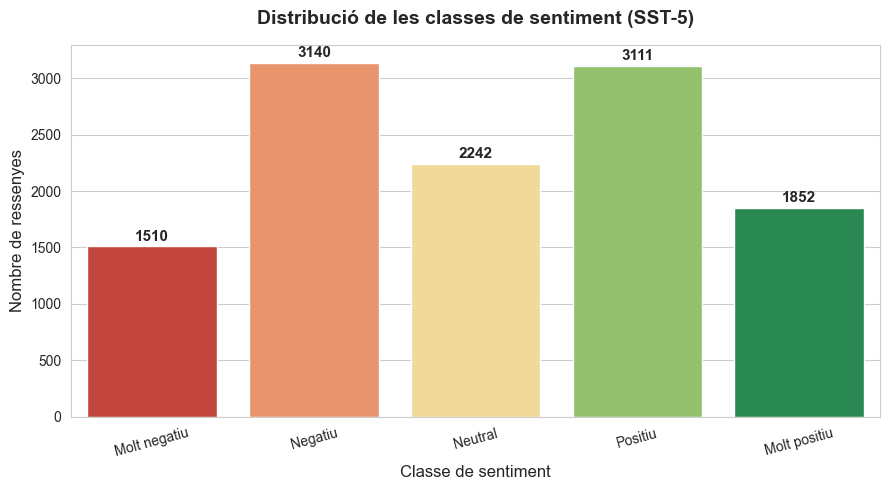

In [23]:
# Configuració de l'estil del gràfic
plt.figure(figsize=(9, 5))
sns.set_style("whitegrid")

# Ordre lògic de les classes
ordre_classes = ["Molt negatiu", "Negatiu", "Neutral", "Positiu", "Molt positiu"]
counts = df["sentiment"].value_counts().reindex(ordre_classes)

# Colors personalitzats per a cada classe
colors = ["#d73027", "#fc8d59", "#fee08b", "#91cf60", "#1a9850"]

# Crear el gràfic de barres
ax = sns.barplot(x=counts.index, y=counts.values, palette=colors)

# Afegir el número a sobre de cada barra
for i, v in enumerate(counts.values):
    #ax.text(nº columna, nº una miqueta per sobre de la barra,...)
    ax.text(i, v + 50, str(v), ha='center', fontweight='bold', fontsize=11)

# Títols i etiquetes
plt.title("Distribució de les classes de sentiment (SST-5)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Classe de sentiment", fontsize=12)
plt.ylabel("Nombre de ressenyes", fontsize=12)
plt.xticks(rotation=15) #Inclinar les etiquetes de l'eix X per a una millor llegibilitat

# Ajustar els marges
plt.tight_layout()

# Guardar la imatge en alta qualitat
plt.savefig("distribucio_classes_sst5.png", dpi=300, bbox_inches='tight')
print("Gràfic guardat com: distribucio_classes_sst5.png")

# Mostrar el gràfic
plt.show()

## 4. Preprocessament del text (es conserva la negació)

La llista estàndard de stopwords en anglès inclou paraules de **negació** (`not`, `no`, `n't`...).  
Per tant, les elimina, convertint *"not good"* en *"good"*, invertint el sentiment.  
Per això es defineix una llista de stopwords que **exclou explícitament** la negació.

In [24]:
lematitzador = WordNetLemmatizer()
paraules_negacio = {
    "no", "not", "nor", "neither", "never", "n't", "cannot",
    "don", "didn", "doesn", "isn", "wasn", "aren", "wouldn",
    "couldn", "shouldn", "won", "hasn", "haven", "ain",
}
paraules_buides = set(stopwords.words("english")) - paraules_negacio


def netejar_text(text):
    #Preprocessament de text que preserva la negació (crític per al sentiment).
    text = BeautifulSoup(str(text), "html.parser").get_text().lower()
    text = re.sub(r"[^a-z\\s']", " ", text)                                 #S'eliminen tots els caracters que no siguin: a-z, espais, apostrofs
    text = re.sub(r"\\s+", " ", text).strip()                               #Sustituïm espais multiples per un sol espai, eliminem els espais a l'inici i final
    tokens = word_tokenize(text)                                            #Dividim el text en una llista de tokens
    tokens = [t for t in tokens if t not in paraules_buides and len(t) > 1] #Eliminem totes les paraules buides o menors d'un caràcter
    tokens = [lematitzador.lemmatize(t) for t in tokens]                    #Reduim totes les paraules de la llista al seu lexema
    return " ".join(tokens)                                                 #Ajuntem tota la llista una altra vegada en una cadena de text


df["text_clean"] = df["text"].apply(netejar_text)
df = df[df["text_clean"].str.strip() != ""].reset_index(drop=True) #Eliminem les lineas buides y tornem a posar tots els indexs de manera que quedin de forma consecutiva
y = df["label"].to_numpy() #Preparem les etiquetes "y" per entrenar el model

print("Exemple de preprocessament amb negació preservada:")
print("Original:", df["text"].iloc[8497])
print("Netejat: ", df["text_clean"].iloc[8497])

Exemple de preprocessament amb negació preservada:
Original: i simply ca n't recommend it enough .
Netejat:  simply ca n't recommend enough


## 5. Divisió train/test estratificada

Com que el nombre de resenyes per clase esta desbalancejat, utilitzem stratify=y per que la divisió en train/test mantingui les proporcions de cada clase

In [25]:
# Amb stratify=y fem que la divisió en train/test mantingui les proporcions de cada clase
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["text_clean"], y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Entrenament: {X_train_text.shape[0]} exemples | Test: {X_test_text.shape[0]} exemples")

Entrenament: 9472 exemples | Test: 2368 exemples


## 6. Vectorització TF-IDF (paraules + caràcters)

Per poder aplicar els models de Machine Learning als comentaris de les pel·lícules, primer és necessari transformar els textos en valors numèrics. Per fer-ho, s'utilitza la tècnica TF-IDF (Term Frequency - Inverse Document Frequency), que assigna un pes a cada terme segons la seva freqüència dins d'un text i la seva importància respecte al conjunt de documents.

En aquest projecte s'utilitzen dos vectoritzadors TF-IDF diferents, ja que cadascun captura un tipus d'informació diferent del text:

- **TF-IDF de paraules** -> utilitza unigrames i bigrames, de manera que pot detectar tant paraules individuals com combinacions de dues paraules. Això permet conservar part del context i expressions com "very good" o "not interesting".<br>

- **TF-IDF de caràcters** -> utilitza n-grames de 3 a 5 caràcters. Aquesta representació permet detectar fragments de paraules i patrons lingüístics, sent especialment útil davant de paraules escrites de manera incorrecta, diferents formes d'una mateixa paraula o variacions morfològiques.<br>

Finalment, les dues representacions es combinen horitzontalment per obtenir una única matriu de característiques que conté tant la informació de les paraules com la informació dels caràcters.<br>

In [26]:
tfidf_paraules = TfidfVectorizer(
    ngram_range=(1, 2),     # Te en compte unigrames i bigrames
    max_features=25000,     # Es queda només amb les 25000 paraules més importants
    min_df=3,               # Ignora termins que apareixin en menys de 3 documents
    max_df=0.9,             # Ignora termins que apareixin en més del 90% del document (paraules masa comunes)
    sublinear_tf=True,      # Aplica transformació logarítmica al TF (redueix el pés de paraules molt frequents)
)
X_train_paraules = tfidf_paraules.fit_transform(X_train_text) # Entrenem el vectoritzador amb textos nets y transforma els textos en una matriu dispersa TF-IDF de paraules
X_test_paraules = tfidf_paraules.transform(X_test_text)

tfidf_caracters = TfidfVectorizer(
    analyzer="char_wb",     # Analitza caracters respetant els limits de paraules (word boundaries)
    ngram_range=(3, 5),     # Utilitza n-gramas de caracters de longitud 3 a 5
    max_features=8000,      # Es queda només amb les 8000 característiques de caràcters més importants
    min_df=3,
    sublinear_tf=True,
)
X_train_caracters = tfidf_caracters.fit_transform(X_train_text) # Entrenem el vectoritzador amb textos nets y transforma els textos en una matriu dispersa TF-IDF de caracters
X_test_caracters = tfidf_caracters.transform(X_test_text) 

# Es combinen horitzontalment les dues matrius disperses
X_train = hstack([X_train_paraules, X_train_caracters]).tocsr() # Ho converteix a CSR (Compressed Sparse Row) una estructura especialment eficient per emmagatzemar i manipular matrius disperses
X_test = hstack([X_test_paraules, X_test_caracters]).tocsr()

print(f"Dimensions TF-IDF paraules (train):   {X_train_paraules.shape}")
print(f"Dimensions TF-IDF paraules (test):    {X_test_paraules.shape}\n")

print(f"Dimensions TF-IDF caràcters (train): {X_train_caracters.shape}")
print(f"Dimensions TF-IDF caràcters (test):  {X_test_caracters.shape}\n")

print(f"Dimensions TF-IDF combinat (train):  {X_train.shape}")
print(f"Dimensions TF-IDF combinat (test):   {X_test.shape}")

Dimensions TF-IDF paraules (train):   (9472, 7572)
Dimensions TF-IDF paraules (test):    (2368, 7572)

Dimensions TF-IDF caràcters (train): (9472, 8000)
Dimensions TF-IDF caràcters (test):  (2368, 8000)

Dimensions TF-IDF combinat (train):  (9472, 15572)
Dimensions TF-IDF combinat (test):   (2368, 15572)


## 7. Balanceig de classes (només si és necessari)

In [27]:
X_train_original = X_train.copy()
y_train_original = y_train.copy()

recompte_train = pd.Series(y_train_original).value_counts() #Contem quantes vegades apareix cada clase
ratio_desequilibri = recompte_train.max() / recompte_train.min() #Dividim la clase més frequent entre la menys frequent

print(f"Ràtio de desequilibri entre classes (train): {ratio_desequilibri:.2f}")

if ratio_desequilibri > 1.5:
    print("Es farà sobremostreig DINS de cada fold del GridSearchCV.")
else:
    print("El dataset ja està raonablement equilibrat.")

# Llista global on s'aniran acumulant els resultats de TOTS els models
resultats_finals = []

Ràtio de desequilibri entre classes (train): 2.08
Es farà sobremostreig DINS de cada fold del GridSearchCV.


## 8. Definició i entrenament de tots els models (TF-IDF)

S'inclouen:
- Models clàssics -> Regressió Logística, Naive Bayes Multinomial, Random Forest, K-Nearest Neighbors i MLP Classifier.<br>
- LinearSVC -> model basat en Support Vector Machines, especialment adequat per treballar amb dades de text representades mitjançant matrius TF-IDF disperses.<br>
- LightGBM / CatBoost -> models de Gradient Boosting basats en arbres de decisió. El programa selecciona automàticament LightGBM si està disponible i utilitza CatBoost com a alternativa en cas contrari.<br>
- XGBoost / Gradient Boosting -> s'inclou XGBoost com a model addicional per completar la comparació. Si la biblioteca XGBoost no està disponible, s'utilitza el GradientBoostingClassifier de Scikit-Learn com a alternativa.<br>

In [28]:
def construir_model_boosting():
    # Retorna el model de Gradient Boosting disponible (LightGBM o CatBoost).
    if MOTOR_BOOSTING == "lightgbm":
        return lgb.LGBMClassifier(
            objective="multiclass",
            num_class=5,
            n_estimators=600,           # Nombre d'arbres a construir
            learning_rate=0.05,         
            num_leaves=31,              # Nombre màxim de fulles per arbre
            class_weight="balanced",    # Ajusta automàticament el pes de cada classe per equilibrar-les
            random_state=RANDOM_STATE,
            n_jobs=-1,                  # Nombre de fils de processament paral·lel a utilitzar (utilitza tots els disponibles)
            verbosity=-1,               # Controla la quantitat de missatges de registre que es mostren durant l'entrenament (-1 = no es mostren missatges de registre).
        )
    else:
        return CatBoostClassifier(
            loss_function="MultiClass",
            iterations=600,             # Nombre d'arbres a construir
            learning_rate=0.05,         
            depth=6,                    # Profunditat màxima de cada arbre
            random_state=RANDOM_STATE, 
            verbose=False,
        )

def construir_models():
    # Diccionari de tots els models a comparar.
    models = {
        # Models Classics
        "Regressió Logística": LogisticRegression(
            solver="lbfgs",             # Algorisme d'optimització per defecte, adequat per a problemes petits i mitjans
            max_iter=3000,              # Nombre màxim d'iteracions per a encontrar la solució optima de l'algorisme
            class_weight="balanced",
            random_state=RANDOM_STATE
        ),
        "Naive Bayes Multinomial": MultinomialNB(),
        "Random Forest": RandomForestClassifier(
            n_estimators=300,           
            class_weight="balanced",    
            random_state=RANDOM_STATE,
            n_jobs=-1                   
        ),
        "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=15, n_jobs=-1), # n_neighbors=15: s'utilitzen els 15 veïns més propers per a la classificació
        "MLP Classifier": MLPClassifier(
            hidden_layer_sizes=(100,),  # Nombre de neurones a la única capa oculta (100). (100,) -> tupla amb un sol element
            max_iter=300,
            random_state=RANDOM_STATE
        ),
        "LinearSVC": CalibratedClassifierCV(    # CalibratedClassifierCV s'utilitza per calibrar les probabilitats de sortida del model LinearSVC, ja que aquest model no proporciona directament probabilitats fiables.
            LinearSVC(class_weight="balanced", random_state=RANDOM_STATE, max_iter=5000),
            cv=5,   # Nombre de folds per a la calibració de probabilitats
        ),
        f"Boosting ({MOTOR_BOOSTING})": construir_model_boosting(),
    }
    # XGBoost es manté a part per completar la comparació
    if XGBOOST_DISPONIBLE:
        models["XGBoost"] = XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.1,
            random_state=RANDOM_STATE,
            eval_metric="mlogloss",     # Funció de pèrdua per a evaluar el problemes multiclasse
            n_jobs=-1,
        )
    else:
        models["Gradient Boosting"] = GradientBoostingClassifier(random_state=RANDOM_STATE)
    return models


# ============================================================
# COMPARACIÓ INICIAL DELS MODELS
# NOMÉS SOBRE TRAIN MITJANÇANT VALIDACIÓ CREUADA
# ============================================================

print("=" * 70)
print("COMPARACIÓ INICIAL DELS MODELS CLÀSSICS (TF-IDF)")
print("Validació creuada sobre TRAIN")
print("=" * 70)

models_inicials = construir_models()

skf_inicial = StratifiedKFold(  # Serveix per a dividir el conjunt de dades en folds estratificats, mantenint la proporció de classes en cada fold.
    n_splits=5,                 # Nombre de folds per a la validació creuada
    shuffle=True,               # Barregem les dades abans de dividir-les en folds per a una millor representativitat
    random_state=RANDOM_STATE
)

resultats_finals = []

for nom, model in models_inicials.items():

    print(f"\nEntrenant: {nom}")

    puntuacions = cross_val_score(      # Avalúa un model utilitzant validació creuada i retorna les puntuacions de la mètrica especificada (f1_macro en aquest cas) per a cada fold.
        model,
        X_train_original,
        y_train_original,
        cv=skf_inicial,         # Diu a la funció quina estratègia de talls utilitzar per dividir les dades (com el StratifiedKFold que hem definit abans).
        scoring="f1_macro",
        n_jobs=-1
    )

    f1_mitja = puntuacions.mean()   # Calcula la mitjana de les puntuacions F1-macro obtingudes en els diferents folds de la validació creuada.
    f1_std = puntuacions.std()      # Calcula la desviació estàndard de les puntuacions F1-macro obtingudes en els diferents folds de la validació creuada.

    resultats_finals.append({
        "Model": nom,
        "Representació": "TF-IDF",
        "F1-macro": round(f1_mitja, 4),
        "F1-macro-std": round(f1_std, 4)
    })

    print(
        f"{nom:35s} -> "                                # Nom del model, alineat a l'esquerra amb un ample de 35 caràcters
        f"F1-macro CV: {f1_mitja:.4f} ± {f1_std:.4f}"   # 
    )

df_resultats_previ = (      # Taula de resultats finals amb els models comparats, ordenada per F1-macro descendent i eliminant duplicats de models.
    pd.DataFrame(resultats_finals)
    .sort_values("F1-macro", ascending=False)
    .drop_duplicates(subset="Model")
)

display(df_resultats_previ)

COMPARACIÓ INICIAL DELS MODELS CLÀSSICS (TF-IDF)
Validació creuada sobre TRAIN

Entrenant: Regressió Logística
Regressió Logística                 -> F1-macro CV: 0.3817 ± 0.0085

Entrenant: Naive Bayes Multinomial
Naive Bayes Multinomial             -> F1-macro CV: 0.3301 ± 0.0070

Entrenant: Random Forest
Random Forest                       -> F1-macro CV: 0.3353 ± 0.0070

Entrenant: K-Nearest Neighbors
K-Nearest Neighbors                 -> F1-macro CV: 0.1897 ± 0.0448

Entrenant: MLP Classifier
MLP Classifier                      -> F1-macro CV: 0.3566 ± 0.0124

Entrenant: LinearSVC
LinearSVC                           -> F1-macro CV: 0.3428 ± 0.0062

Entrenant: Boosting (lightgbm)
Boosting (lightgbm)                 -> F1-macro CV: 0.3416 ± 0.0081

Entrenant: XGBoost
XGBoost                             -> F1-macro CV: 0.3206 ± 0.0048


,Model,Representació,F1-macro,F1-macro-std
0,Regressió Logística,TF-IDF,0.3817,0.0085
4,MLP Classifier,TF-IDF,0.3566,0.0124
5,LinearSVC,TF-IDF,0.3428,0.0062
6,Boosting (lightgbm),TF-IDF,0.3416,0.0081
2,Random Forest,TF-IDF,0.3353,0.0070
1,Naive Bayes Multinomial,TF-IDF,0.3301,0.0070
7,XGBoost,TF-IDF,0.3206,0.0048
3,K-Nearest Neighbors,TF-IDF,0.1897,0.0448


## 8.1 Cerca dels millors hiperparàmetres (només per als 3 millors models)

Ara que ja sabem quins són els 3 millors models de la secció 8 (per F1-macro), optimitzem **només aquests** amb `GridSearchCV`. Els models optimitzats (`millors_models`) es reutilitzaran directament al `VotingClassifier` de la secció 9, en lloc de tornar a crear versions amb hiperparàmetres per defecte.


In [29]:
# ============================================================
# GRIDSEARCHCV CORRECTE
#
# TRAIN ORIGINAL
#       ↓
# GridSearchCV
#       ↓
# Fold train → Oversampling → Model
# Fold val   → SIN oversampling
#       ↓
# Millors hiperparàmetres
# ============================================================





# ------------------------------------------------------------
# Seleccionem els 3 millors models segons la CV inicial
# ------------------------------------------------------------

top_3_noms = (
    df_resultats_previ["Model"]
    .drop_duplicates()
    .tolist()[:3]
)

print(f"\nModels seleccionats per optimitzar: {top_3_noms}")


# ------------------------------------------------------------
# GridSearch de cada model
# ------------------------------------------------------------

grids_candidats = {

    # ========================================================
    # LOGISTIC REGRESSION
    # ========================================================

    "Regressió Logística": (

        Pipeline([
            ("oversampler", RandomOverSampler(
                random_state=RANDOM_STATE
            )),
            ("classifier", LogisticRegression(
                max_iter=3000,
                random_state=RANDOM_STATE
            ))
        ]),

        {
            "classifier__C": [0.1, 0.5, 1, 2, 5, 10],       # constant de regularització. Valors més petits = més regularització, valors més grans = menys regularització.
            "classifier__solver": ["lbfgs"],                # Algorisme d'optimització per defecte, adequat per a problemes petits i mitjans.
            "classifier__class_weight": [None, "balanced"]  # Si s'estableix a "balanced", ajusta automàticament els pesos de les classes inversament proporcionals a la seva freqüència en les dades d'entrenament.
        }
    ),


    # ========================================================
    # NAIVE BAYES
    # ========================================================

    "Naive Bayes Multinomial": (

        Pipeline([
            ("oversampler", RandomOverSampler(
                random_state=RANDOM_STATE
            )),
            ("classifier", MultinomialNB())
        ]),

        {
            "classifier__alpha": [      # constant de suavitzat de Laplace. Valors més petits = menys suavitzat, valors més grans = més suavitzat.
                0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0
            ]
        }
    ),


    # ========================================================
    # RANDOM FOREST
    # ========================================================

    "Random Forest": (

        Pipeline([
            ("oversampler", RandomOverSampler(
                random_state=RANDOM_STATE
            )),
            ("classifier", RandomForestClassifier(
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
        ]),

        {
            "classifier__n_estimators": [200, 300, 500],
            "classifier__max_depth": [None, 20, 40],
            "classifier__class_weight": [None, "balanced"]
        }
    ),


    # ========================================================
    # KNN
    # ========================================================

    "K-Nearest Neighbors": (

        Pipeline([
            ("oversampler", RandomOverSampler(
                random_state=RANDOM_STATE
            )),
            ("classifier", KNeighborsClassifier(
                n_jobs=-1
            ))
        ]),

        {
            "classifier__n_neighbors": [5, 10, 15, 25],
            "classifier__weights": ["uniform", "distance"]
        }
    ),


    # ========================================================
    # MLP
    # ========================================================

    "MLP Classifier": (

        Pipeline([
            ("oversampler", RandomOverSampler(
                random_state=RANDOM_STATE
            )),
            ("classifier", MLPClassifier(
                max_iter=300,
                random_state=RANDOM_STATE
            ))
        ]),

        {
            "classifier__hidden_layer_sizes": [
                (50,),
                (100,),
                (100, 50)
            ],
            "classifier__alpha": [
                0.0001,
                0.001,
                0.01
            ]
        }
    ),


    # ========================================================
    # LINEAR SVC
    # ========================================================

    "LinearSVC": (

        Pipeline([
            ("oversampler", RandomOverSampler(
                random_state=RANDOM_STATE
            )),
            ("classifier", LinearSVC(
                random_state=RANDOM_STATE,
                max_iter=5000
            ))
        ]),

        {
            "classifier__C": [
                0.01, 0.1, 0.5, 1, 2, 5, 10
            ],
            "classifier__class_weight": [
                None,
                "balanced"
            ]
        }
    ),


    # ========================================================
    # LIGHTGBM
    # ========================================================

    f"Boosting ({MOTOR_BOOSTING})": (

        Pipeline([
            ("oversampler", RandomOverSampler(
                random_state=RANDOM_STATE
            )),
            ("classifier", construir_model_boosting())
        ]),

        {
            "classifier__n_estimators": [50, 100, 200],
            "classifier__learning_rate": [0.01, 0.05, 0.1],
            "classifier__num_leaves": [15, 31, 63]
        }
        if MOTOR_BOOSTING == "lightgbm"

        else

        {
            "classifier__iterations": [200, 400, 600],
            "classifier__learning_rate": [0.01, 0.05, 0.1],
            "classifier__depth": [4, 6, 8]
        }
    )
}


# ============================================================
# XGBOOST
# ============================================================

if XGBOOST_DISPONIBLE:

    grids_candidats["XGBoost"] = (

        Pipeline([
            ("oversampler", RandomOverSampler(
                random_state=RANDOM_STATE
            )),
            ("classifier", XGBClassifier(
                random_state=RANDOM_STATE,
                eval_metric="mlogloss",
                n_jobs=-1
            ))
        ]),

        {
            "classifier__n_estimators": [100, 200, 300],
            "classifier__max_depth": [4, 6, 8],
            "classifier__learning_rate": [0.01, 0.05, 0.1]
        }
    )


# ============================================================
# GRIDSEARCH
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

resultats_gridsearch = []
millors_models = {}

for nom in top_3_noms:

    if nom not in grids_candidats:

        print(
            f"[Avís] No hi ha graella definida per "
            f"'{nom}'."
        )

        continue

    model, param_grid = grids_candidats[nom]

    print("\n" + "=" * 70)
    print(f"GRIDSEARCHCV: {nom}")
    print("=" * 70)

    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grid,  # Diccionari amb els hiperparàmetres a provar. Cada clau correspon a un hiperparàmetre del model i el seu valor és una llista de valors possibles.
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        verbose=1,
        refit=True              # Indica que després de trobar els millors hiperparàmetres, el model s'entrenarà de nou amb tot el conjunt de dades d'entrenament utilitzant aquests hiperparàmetres.
    )

    # IMPORTANT:
    # s'utilitza el TRAIN ORIGINAL.
    # El pipeline fa el oversampling DINS de cada fold.
    grid.fit(
        X_train_original,
        y_train_original
    )

    # Millor pipeline ja entrenat amb TOT el train
    millors_models[nom] = grid.best_estimator_

    resultats_gridsearch.append({
        "Model": nom,
        "Millors hiperparàmetres": grid.best_params_,
        "Millor F1-macro CV": round(grid.best_score_, 4)
    })

    print(
        f"\nMillors hiperparàmetres: "
        f"{grid.best_params_}"
    )

    print(
        f"Millor F1-macro CV: "
        f"{grid.best_score_:.4f}"
    )

# ============================================================
# CALIBRACIÓ DE PROBABILITATS (LinearSVC)
# ============================================================
# CalibratedClassifierCV és una tècnica per fer que el model LinearSVC aprengui a donar probabilitats reals (de 0% a 100%) per a cada tipus de ressenya, ja que per defecte aquest algorisme només sap classificar directament sense dir com n'està de segur.
if "LinearSVC" in millors_models:

    pipeline_svc = millors_models["LinearSVC"]

    calibrated_svc = CalibratedClassifierCV(
        estimator=pipeline_svc,
        cv=5,
        n_jobs=-1
    )
    
    # IMPORTANT: El tornem a entrenar amb les dades originals perquè aprengui les probabilitats
    calibrated_svc.fit(X_train_original, y_train_original)
    
    # Substituïm el model base pel calibrat
    millors_models["LinearSVC"] = calibrated_svc

df_gridsearch = pd.DataFrame(
    resultats_gridsearch
)

print("\n" + "=" * 70)
print("RESULTATS GRIDSEARCHCV")
print("=" * 70)

display(df_gridsearch)


Models seleccionats per optimitzar: ['Regressió Logística', 'MLP Classifier', 'LinearSVC']

GRIDSEARCHCV: Regressió Logística
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Millors hiperparàmetres: {'classifier__C': 0.5, 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}
Millor F1-macro CV: 0.3812

GRIDSEARCHCV: MLP Classifier
Fitting 5 folds for each of 9 candidates, totalling 45 fits

Millors hiperparàmetres: {'classifier__alpha': 0.0001, 'classifier__hidden_layer_sizes': (50,)}
Millor F1-macro CV: 0.3587

GRIDSEARCHCV: LinearSVC
Fitting 5 folds for each of 14 candidates, totalling 70 fits

Millors hiperparàmetres: {'classifier__C': 0.1, 'classifier__class_weight': None}
Millor F1-macro CV: 0.3729

RESULTATS GRIDSEARCHCV


,Model,Millors hiperparàmetres,Millor F1-macro CV
0,Regressió Logística,"{'classifier__C': 0.5, 'classifier__class_weig...",0.3812
1,MLP Classifier,"{'classifier__alpha': 0.0001, 'classifier__hid...",0.3587
2,LinearSVC,"{'classifier__C': 0.1, 'classifier__class_weig...",0.3729


# 8.1 EVALUACIÓ FINAL SOBRE TEST

L'EVALUACIÓ FINAL SOBRE TEST és el procés definitiu on es proven els 3 millors models configurats amb un conjunt de dades totalment nou (``X_test``) que mai abans havien vist, calculant les mètriques reals per saber com funcionarà el model en el món real.

In [30]:
# ============================================================
# EVALUACIÓ FINAL SOBRE TEST
#
# X_test NO s'ha utilitzat per seleccionar hiperparàmetres.
# ============================================================

resultats_grid_test = []

for nom, model in millors_models.items():

    print(f"\nAvaluant: {nom}")

    # El millor pipeline es torna a entrenar sobre TOT el train
    model.fit(
        X_train_original,
        y_train_original
    )

    # ÚNIC punt on utilitzem X_test
    pred = model.predict(X_test)

    acc = accuracy_score(
        y_test,
        pred
    )

    _, _, f1_macro, _ = precision_recall_fscore_support(
        y_test,
        pred,
        average="macro",    # Calcula la mitjana de les mètriques per a cada classe, sense tenir en compte el desequilibri de classes.
        zero_division=0     # Si alguna classe no té prediccions, evita errors retornant 0 en lloc de generar una excepció.
    )

    _, _, f1_weighted, _ = precision_recall_fscore_support(
        y_test,
        pred,
        average="weighted",     # Calcula la mitjana de les mètriques per a cada classe, ponderant-les segons la seva freqüència en el conjunt de dades.
        zero_division=0         
    )

    resultats_grid_test.append({
        "Model": nom,
        "Accuracy": round(acc, 4),
        "F1-macro": round(f1_macro, 4),
        "F1-weighted": round(f1_weighted, 4)
    })


df_grid_test = (
    pd.DataFrame(resultats_grid_test)
    .sort_values("F1-macro", ascending=False)
)

print("\n" + "=" * 70)
print("RESULTATS FINALS SOBRE TEST")
print("=" * 70)

display(df_grid_test)


Avaluant: Regressió Logística

Avaluant: MLP Classifier

Avaluant: LinearSVC

RESULTATS FINALS SOBRE TEST


,Model,Accuracy,F1-macro,F1-weighted
0,Regressió Logística,0.3725,0.3715,0.3718
2,LinearSVC,0.4020,0.3620,0.3773
1,MLP Classifier,0.3530,0.3448,0.3530


## 9. VotingClassifier (soft) amb els millors models (ja amb hiperparàmetres optimitzats)

``VotingClassifier`` és una tècnica d'aprenentatge conjunt (ensemble) que combina els teus 3 millors models per fer-los treballar en equip, sumant els seus percentatges de probabilitat (voting="soft") per prendre una decisió final consensuada i obtenir, generalment, una predicció més robusta.

In [31]:
# ============================================================
# VOTING CLASSIFIER
# ============================================================

estimadors_voting = [
    (nom, millors_models[nom])
    for nom in top_3_noms
    if nom in millors_models
]

print(
    f"Models al VotingClassifier: "
    f"{[n for n, _ in estimadors_voting]}"
)

voting = VotingClassifier(
    estimators=estimadors_voting,
    voting="soft",      # Utilitza les probabilitats de cada model per fer la predicció final (en lloc de només el vot majoritari).
    n_jobs=-1
)

# Entrenament FINAL només amb train
voting.fit(
    X_train_original,
    y_train_original
)

# Test FINAL
pred_voting = np.asarray(       # Convertim la sortida a un array de NumPy per facilitar el càlcul de les mètriques.
    voting.predict(X_test)      
).flatten()                     # flatten() s'utilitza per convertir qualsevol estructura multidimensional en un array unidimensional, assegurant que les prediccions estiguin en el format correcte.

acc_voting = accuracy_score(
    y_test,
    pred_voting
)

_, _, f1_voting, _ = precision_recall_fscore_support(
    y_test,
    pred_voting,
    average="macro",
    zero_division=0
)

_, _, f1w_voting, _ = precision_recall_fscore_support(
    y_test,
    pred_voting,
    average="weighted",
    zero_division=0
)

print(
    f"\nVotingClassifier -> "
    f"Accuracy: {acc_voting:.4f} | "
    f"F1-macro: {f1_voting:.4f} | "
    f"F1-weighted: {f1w_voting:.4f}"
)

Models al VotingClassifier: ['Regressió Logística', 'MLP Classifier', 'LinearSVC']

VotingClassifier -> Accuracy: 0.3615 | F1-macro: 0.3539 | F1-weighted: 0.3610


## 10. Sentence-Transformers (all-MiniLM-L6-v2) + classificador clàssic

Aquesta és la tècnica amb **més potencial de millora** sense fine-tuning pesat.  
S'utilitza el text **original** (sense eliminar stopwords), perquè el model espera llenguatge natural complet.

Sentence-Transformers és una tècnica avançada que converteix cada ressenya de text en un vector numèric (embedding) que captura el significat conceptual i el context del llenguatge natural per després classificar-lo amb algorismes clàssics.

In [37]:
if EXECUTAR_EMBEDDINGS:
    print("=" * 70)
    print("SENTENCE-TRANSFORMERS (all-MiniLM-L6-v2) + CLASSIFICADOR CLÀSSIC")
    print("=" * 70)

    from sentence_transformers import SentenceTransformer

    model_embeddings = SentenceTransformer("all-MiniLM-L6-v2")  # Descarrega i prepara un model de Deep Learning preentrenat que destaca per ser molt ràpid i eficient a l'hora d'entendre la semàntica del text.

    # Transforma els textos originals en una matriu de nombres (vectors). Processa les frases senceres en lots de 64 (batch_size=64) per no saturar la memòria de l'ordinador.
    X_embed = model_embeddings.encode(
        df["text"].tolist(), batch_size=64, show_progress_bar=True, 
    )
    # Divideix els nous vectors en conjunts d'entrenament i test, assegurant un cop més que la proporció de les 5 classes de ressenyes es mantingui idèntica a ambdós costats.
    X_train_emb, X_test_emb, y_train_emb, y_test_emb = train_test_split(
        X_embed, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
    )

    # Balanceig (si cal) també sobre els embeddings d'entrenament
    if ratio_desequilibri > 1.5:
        sobremostreig_emb = RandomOverSampler(random_state=RANDOM_STATE)
        X_train_emb, y_train_emb = sobremostreig_emb.fit_resample(X_train_emb, y_train_emb)

    classificadors_embedding = {
        "Embeddings + Regressió Logística": LogisticRegression(
            max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE
        ),
        #Integra directament la calibració de probabilitats al LinearSVC des del principi per evitar haver de fer-ho posteriorment a mà, tal com hem vist en els passos anteriors.
        "Embeddings + LinearSVC": CalibratedClassifierCV(
            LinearSVC(class_weight="balanced", random_state=RANDOM_STATE, max_iter=5000), cv=5
        ),
    }

    pred_emb = {}

    pred_emb = {}

for nom, clf in classificadors_embedding.items():
    clf.fit(X_train_emb, y_train_emb)

    pred_emb[nom] = clf.predict(X_test_emb)

    acc_emb = accuracy_score(y_test_emb, pred_emb[nom])

    _, _, f1_emb, _ = precision_recall_fscore_support(
        y_test_emb,
        pred_emb[nom],
        average="macro",
        zero_division=0
    )

    _, _, f1w_emb, _ = precision_recall_fscore_support(
        y_test_emb,
        pred_emb[nom],
        average="weighted",
        zero_division=0
    )

    resultats_finals.append({
        "Model": nom,
        "Representació": "Sentence-Embeddings",
        "Accuracy": round(acc_emb, 4),
        "F1-macro": round(f1_emb, 4),
        "F1-weighted": round(f1w_emb, 4),
    })

    print(
        f"{nom:35s} -> "
        f"Accuracy: {acc_emb:.4f} | "
        f"F1-macro: {f1_emb:.4f}"
    )
else:
    print("[EXECUTAR_EMBEDDINGS = False] S'omet la secció de Sentence-Transformers.")

SENTENCE-TRANSFORMERS (all-MiniLM-L6-v2) + CLASSIFICADOR CLÀSSIC


Batches: 100%|██████████| 185/185 [00:58<00:00,  3.14it/s]


Embeddings + Regressió Logística    -> Accuracy: 0.3936 | F1-macro: 0.3944
Embeddings + LinearSVC              -> Accuracy: 0.3809 | F1-macro: 0.3807
[EXECUTAR_EMBEDDINGS = False] S'omet la secció de Sentence-Transformers.


## 11. Taula comparativa final de tots els models

Aquest bloc de codi reuneix tots els resultats del projecte en una taula resum definitiva ordenada de millor a pitjor i genera un gràfic de barres horitzontals que compara visualment el rendiment (F1-macro) de cada mètode.

TAULA COMPARATIVA FINAL DE TOTS ELS MODELS (ordenada per F1-macro)


,Model,Representació,F1-macro,F1-macro-std,Accuracy,F1-weighted
1,Embeddings + Regressió Logística,Sentence-Embeddings,0.3944,NaN,0.3936,0.3904
2,Embeddings + Regressió Logística,Sentence-Embeddings,0.3944,NaN,0.3936,0.3904
3,Regressió Logística,TF-IDF,0.3817,0.0085,NaN,NaN
4,Embeddings + LinearSVC,Sentence-Embeddings,0.3807,NaN,0.3809,0.3726
5,Embeddings + LinearSVC,Sentence-Embeddings,0.3807,NaN,0.3809,0.3726
6,MLP Classifier,TF-IDF,0.3566,0.0124,NaN,NaN
7,LinearSVC,TF-IDF,0.3428,0.0062,NaN,NaN
8,Boosting (lightgbm),TF-IDF,0.3416,0.0081,NaN,NaN
9,Random Forest,TF-IDF,0.3353,0.0070,NaN,NaN
10,Naive Bayes Multinomial,TF-IDF,0.3301,0.0070,NaN,NaN


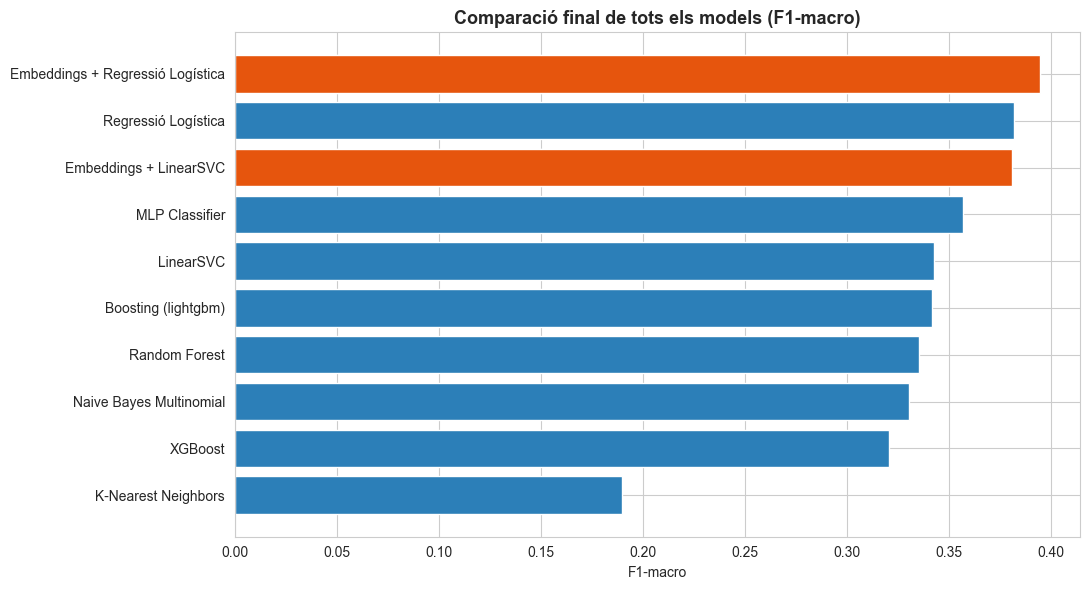


Procés complet finalitzat correctament.


In [38]:
df_comparativa_final = pd.DataFrame(resultats_finals).sort_values(
    "F1-macro", ascending=False
).reset_index(drop=True)
df_comparativa_final.index += 1  # numeració des d'1

print("=" * 78)
print("TAULA COMPARATIVA FINAL DE TOTS ELS MODELS (ordenada per F1-macro)")
print("=" * 78)
display(df_comparativa_final)

# Gràfic comparatiu final
fig, ax = plt.subplots(figsize=(11, 6))
colors_barres = ["#2c7fb8" if r == "TF-IDF" else ("#e6550d" if r == "Sentence-Embeddings" else "#31a354")
                  for r in df_comparativa_final["Representació"]]
ax.barh(df_comparativa_final["Model"][::-1], df_comparativa_final["F1-macro"][::-1], color=colors_barres[::-1])
ax.set_xlabel("F1-macro")
ax.set_title("Comparació final de tots els models (F1-macro)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("\nProcés complet finalitzat correctament.")

# Ultimos Retoques
### Grafics:
- Wordclouds 5 clases
- paraules frequents de las 5 clases
- matriu de confusio dels 3 millors models per TF-IDF
- matriu de confusio dels 2 models per Sentence-Embeddings

## Altres comprobacións de codi:
- Comprobar si hi ha blocs de codi extra o linees que no s'hagin utilitzat

## Part Escrita del TR
- Bibliogra
- anexos
- peus de foto
- text explicatiu (basantse en les anotacions del codi) amb les imatges generades pels grafics

Gràfic guardat com: wordclouds_classes_sst5.png


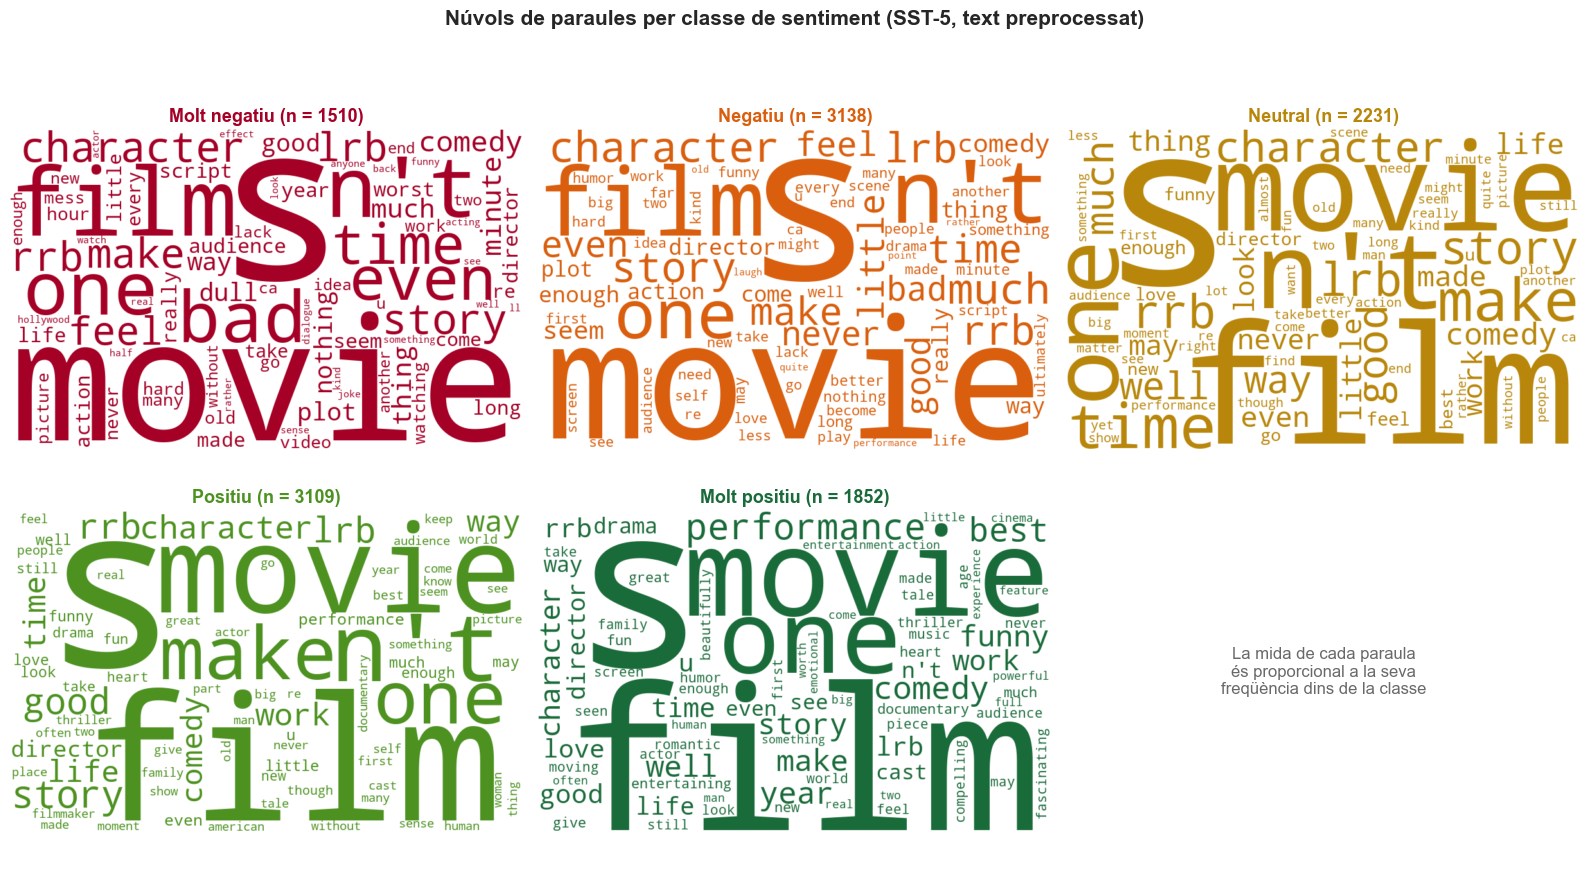

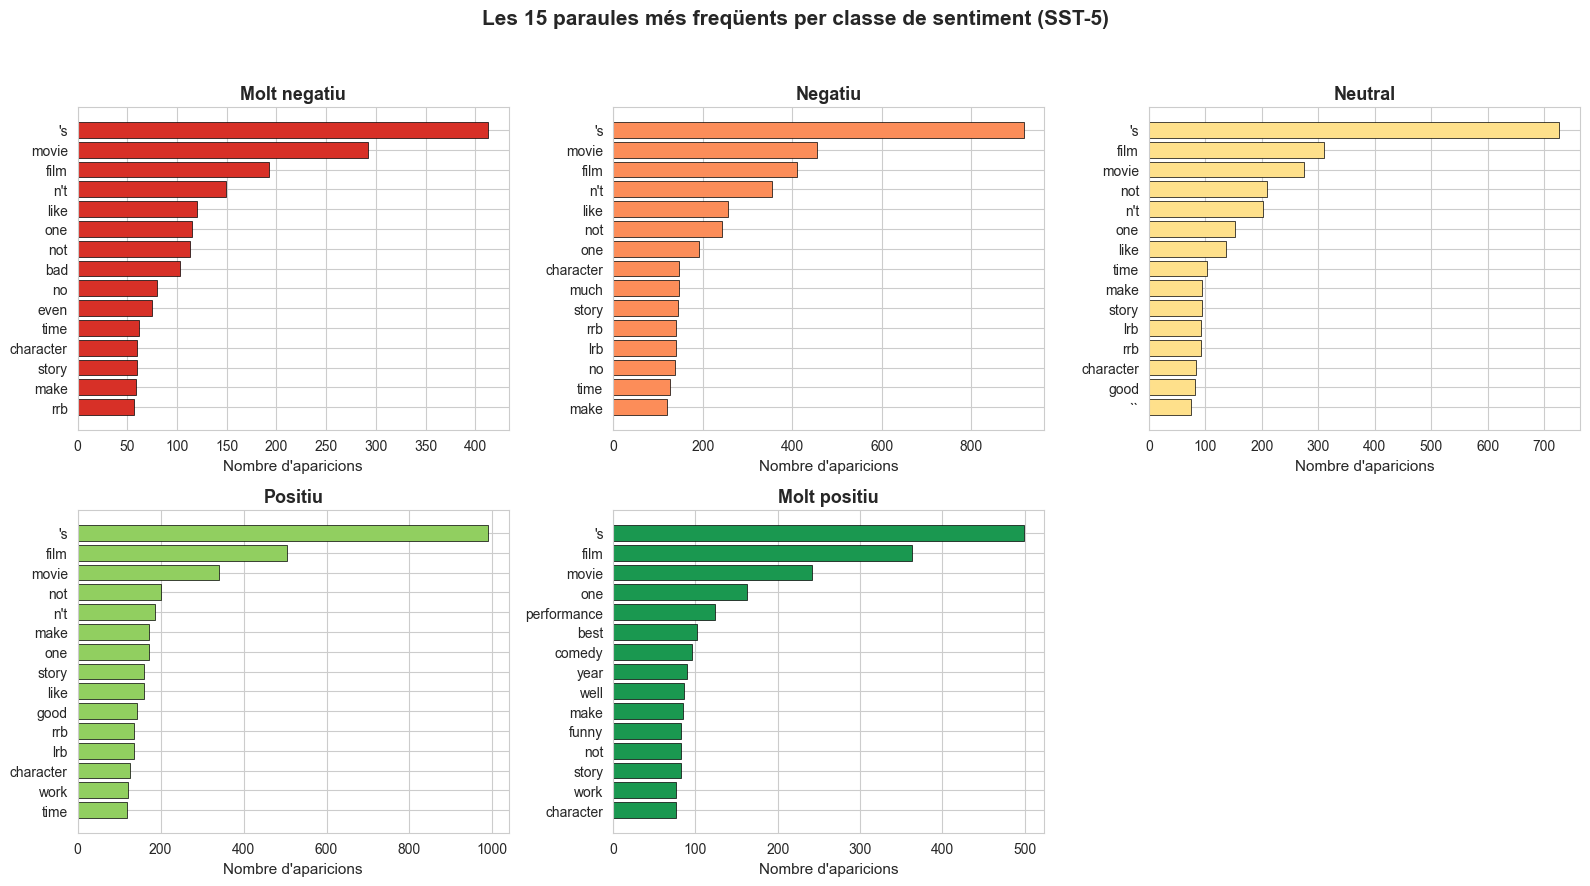

,Molt negatiu,Negatiu,Neutral,Positiu,Molt positiu
1,'s (413),'s (917),'s (727),'s (990),'s (499)
2,movie (292),movie (455),film (311),film (504),film (363)
3,film (192),film (410),movie (274),movie (340),movie (241)
4,n't (149),n't (355),not (209),not (202),one (162)
5,like (120),like (256),n't (203),n't (187),performance (124)
6,one (115),not (243),one (152),make (173),best (102)
7,not (113),one (192),like (137),one (173),comedy (96)
8,bad (103),character (148),time (103),story (160),year (90)
9,no (80),much (147),make (94),like (160),well (86)
10,even (75),story (144),story (94),good (144),make (85)


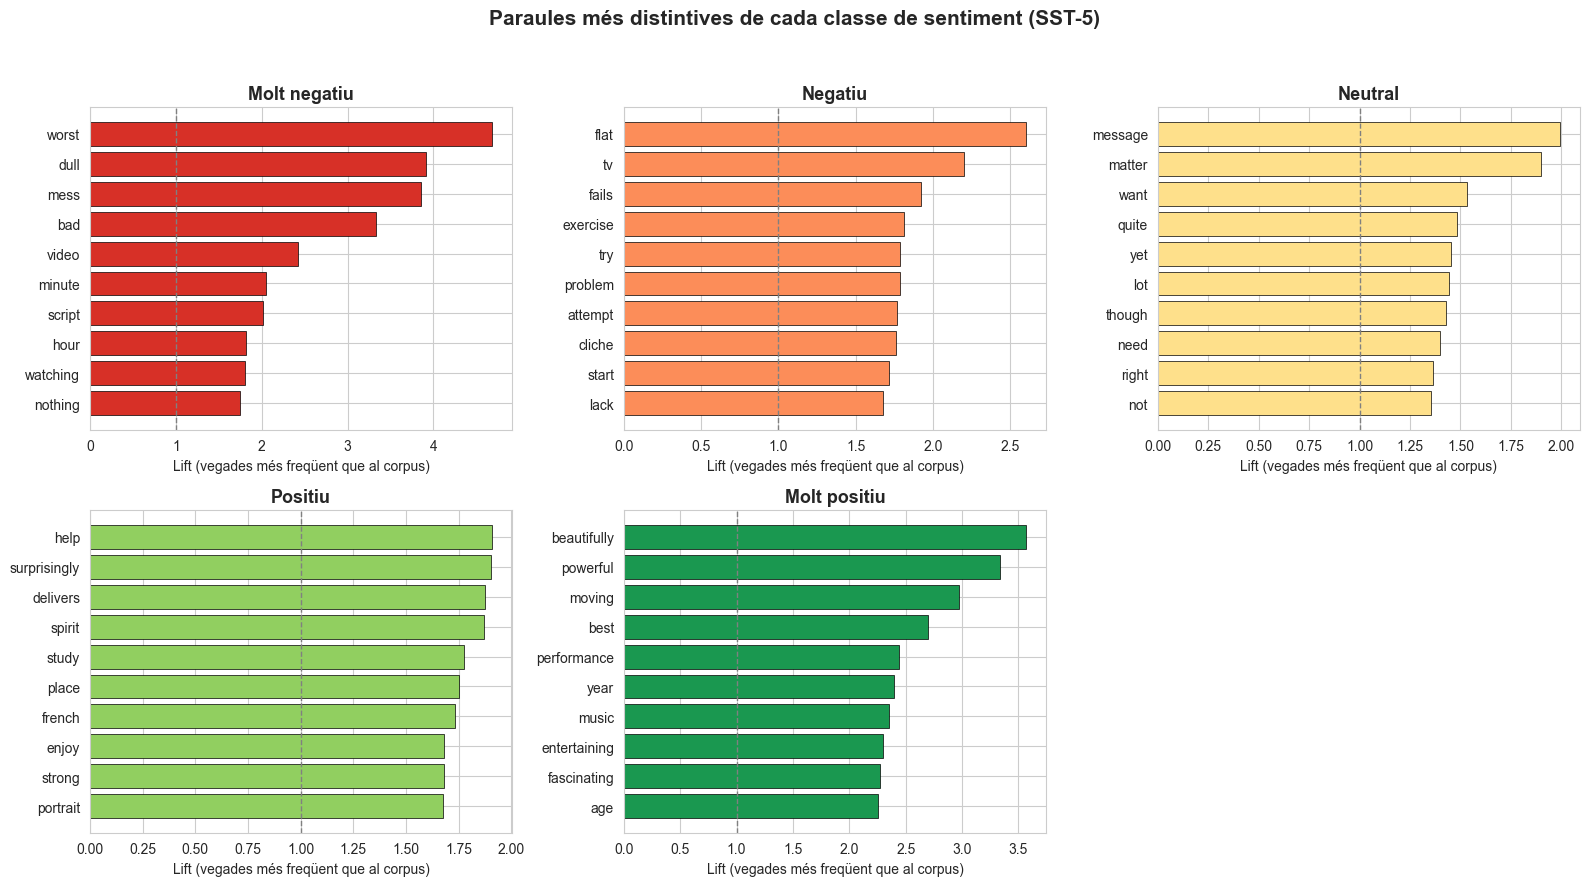

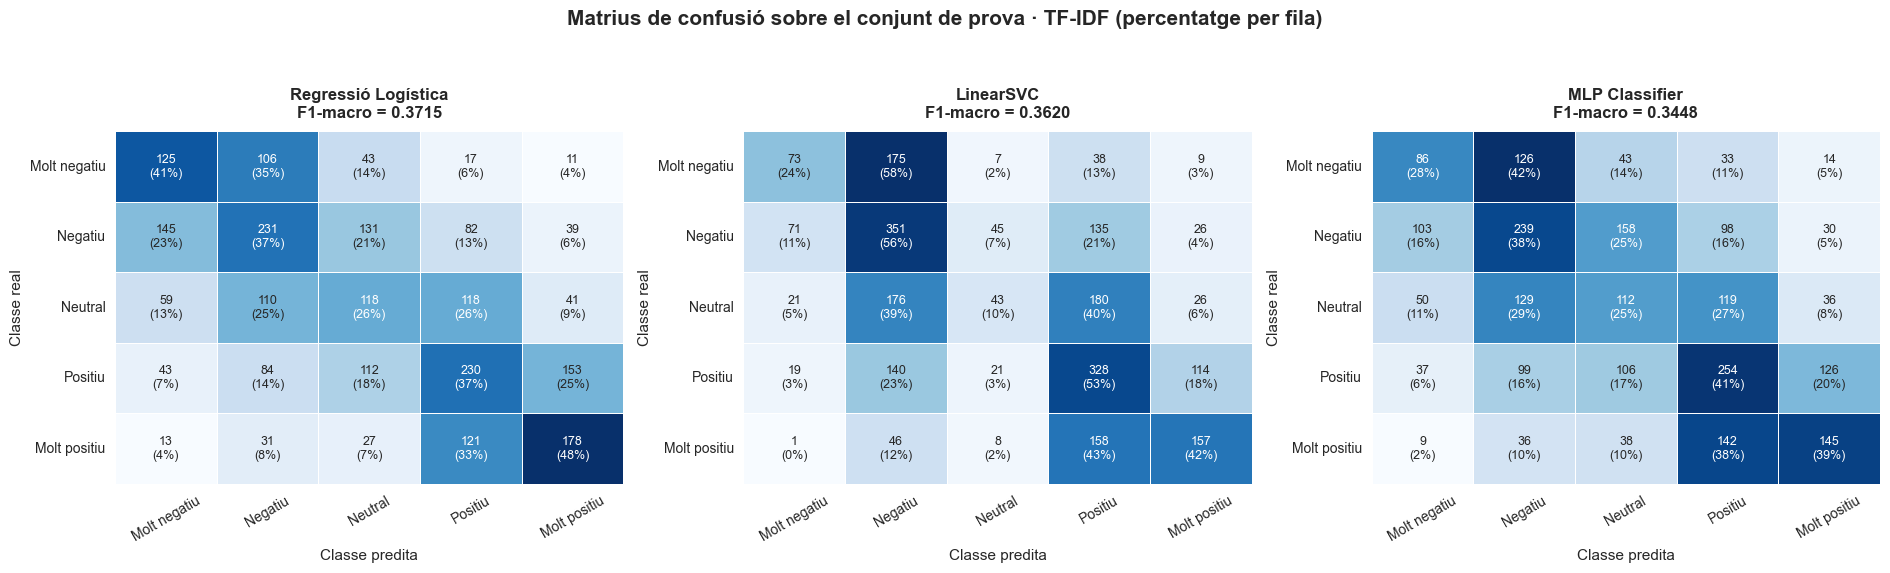

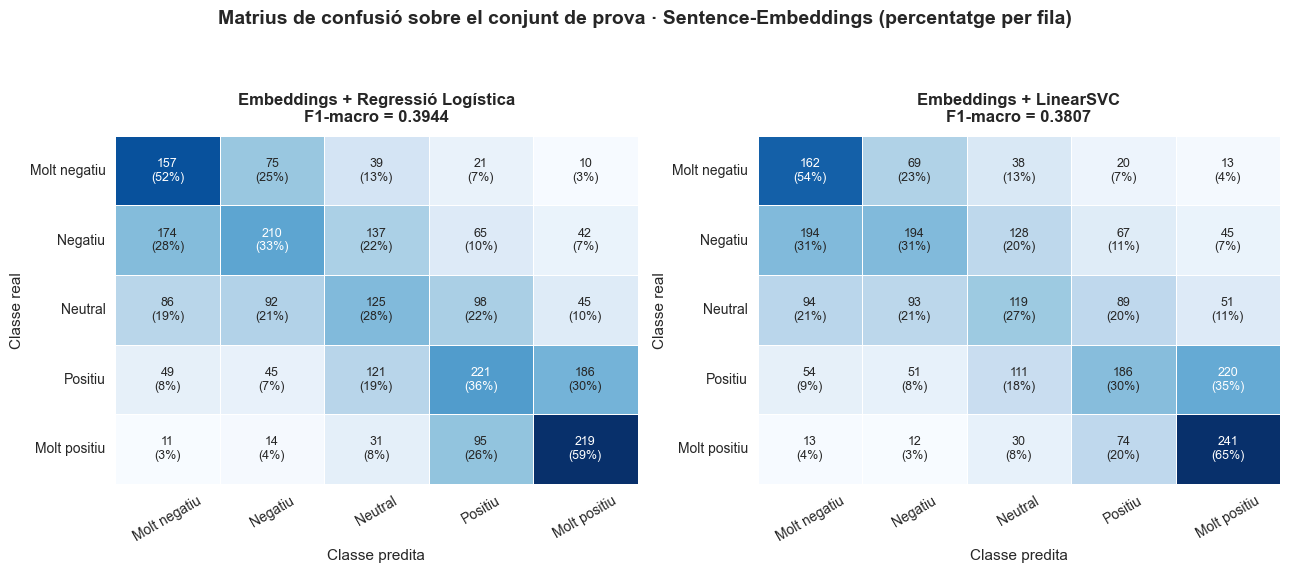

,Model,Representació,Accuracy,F1-macro,F1-weighted
1,Embeddings + Regressió Logística,Sentence-Embeddings,0.3936,0.3944,0.3904
2,Embeddings + Regressió Logística,Sentence-Embeddings,0.3936,0.3944,0.3904
3,Embeddings + LinearSVC,Sentence-Embeddings,0.3809,0.3807,0.3726
4,Embeddings + LinearSVC,Sentence-Embeddings,0.3809,0.3807,0.3726
5,Regressió Logística,TF-IDF,0.3725,0.3715,0.3718
6,LinearSVC,TF-IDF,0.4020,0.3620,0.3773
7,VotingClassifier (soft),TF-IDF + votació,0.3615,0.3539,0.3610
8,MLP Classifier,TF-IDF,0.3530,0.3448,0.3530


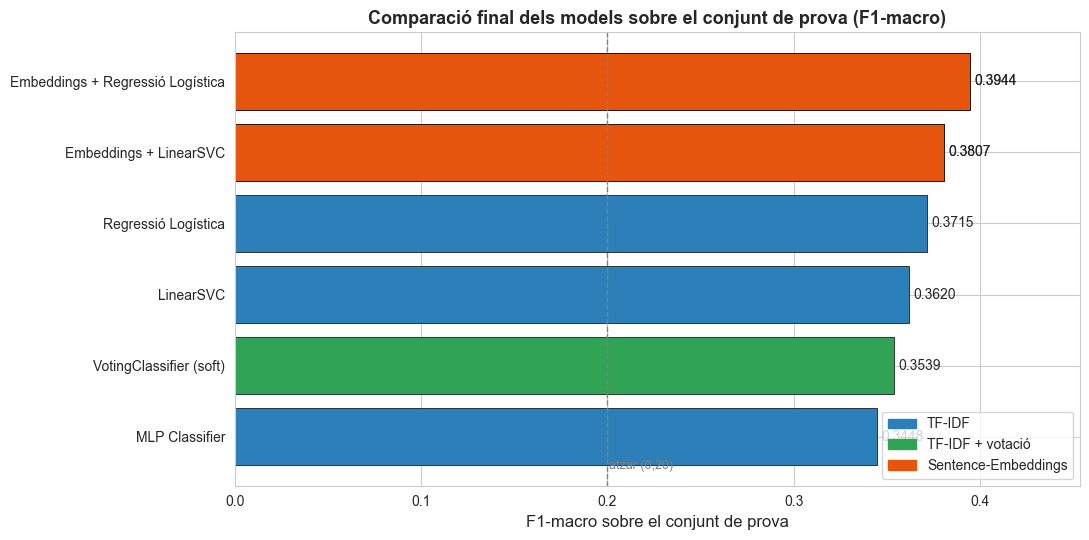

In [39]:
# ==============================================================================
# CODI DELS GRÀFICS PENDENTS · Treball de Recerca (SST-5)
# Copia cada bloc en una cel·la nova del notebook, DESPRÉS de la secció 11.
# Abans, aplica la modificació de la cel·la 29 (prediccions_emb) i les
# correccions de l'informe (apartat 4). Bloc provat amb dades simulades.
# ==============================================================================

# %% [1. PREPARACIÓ COMUNA]
# ==============================================================================
# GRÀFICS PENDENTS · Preparació comuna
# ==============================================================================
from collections import Counter
from wordcloud import WordCloud
from sklearn.metrics import confusion_matrix, f1_score

sns.set_style("whitegrid")

# Mateixa paleta que el gràfic de distribució de classes
COLORS_CLASSES = ["#d73027", "#fc8d59", "#fee08b", "#91cf60", "#1a9850"]
# Versió més fosca per als textos (el groc clar no es llegeix sobre fons blanc)
COLORS_TEXT = ["#a50026", "#d95f0e", "#b8860b", "#4d9221", "#1a6b3a"]

# %% [2. NÚVOLS DE PARAULES]
# ==============================================================================
# GRÀFIC 1 · Núvols de paraules per classe de sentiment
# ==============================================================================
def color_uniforme(color):
    """Retorna una funció que pinta totes les paraules del núvol del mateix color."""
    return lambda *args, **kwargs: color

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, nom in enumerate(noms_classes):
    # Text preprocessat (sense stopwords, lematitzat, amb negació) de la classe i
    text_classe = " ".join(df.loc[df["label"] == i, "text_clean"])
    nuvol = WordCloud(
        width=800, height=500, background_color="white",
        max_words=80, collocations=False,          # collocations=False evita bigrames repetits
        color_func=color_uniforme(COLORS_TEXT[i]),
        random_state=RANDOM_STATE,
    ).generate(text_classe)

    axes[i].imshow(nuvol, interpolation="bilinear")
    axes[i].set_title(f"{nom} (n = {(df['label'] == i).sum()})",
                      fontsize=13, fontweight="bold", color=COLORS_TEXT[i])
    axes[i].axis("off")

# Sisè quadre: nota explicativa
axes[5].axis("off")
axes[5].text(0.5, 0.5, "La mida de cada paraula\nés proporcional a la seva\nfreqüència dins de la classe",
             ha="center", va="center", fontsize=12, color="dimgray")

fig.suptitle("Núvols de paraules per classe de sentiment (SST-5, text preprocessat)",
             fontsize=15, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("wordclouds_classes_sst5.png", dpi=300, bbox_inches="tight")
print("Gràfic guardat com: wordclouds_classes_sst5.png")
plt.show()

# %% [3. PARAULES FREQÜENTS]
# ==============================================================================
# GRÀFIC 2 · Paraules més freqüents per classe (barres + taula)
# ==============================================================================
N_TOP = 15

top_paraules = {}
for i, nom in enumerate(noms_classes):
    comptador = Counter(p for t in df.loc[df["label"] == i, "text_clean"] for p in t.split())
    top_paraules[nom] = comptador.most_common(N_TOP)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, nom in enumerate(noms_classes):
    paraules, freqs = zip(*top_paraules[nom])
    axes[i].barh(paraules[::-1], freqs[::-1], color=COLORS_CLASSES[i],
                 edgecolor="black", linewidth=0.5)          # [::-1]: la més freqüent a dalt
    axes[i].set_title(nom, fontsize=13, fontweight="bold")
    axes[i].set_xlabel("Nombre d'aparicions", fontsize=11)
axes[5].axis("off")

fig.suptitle(f"Les {N_TOP} paraules més freqüents per classe de sentiment (SST-5)",
             fontsize=15, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("paraules_frequents_classes_sst5.png", dpi=300, bbox_inches="tight")
plt.show()

# Taula equivalent (útil per a l'Annex B)
df_top_paraules = pd.DataFrame(
    {nom: [f"{p} ({f})" for p, f in top_paraules[nom]] for nom in noms_classes}
)
df_top_paraules.index += 1
display(df_top_paraules)

# %% [4. PARAULES DISTINTIVES (opcional)]
# ==============================================================================
# GRÀFIC 2b · Paraules més distintives per classe (lift respecte al corpus)
# ==============================================================================
MIN_APARICIONS = 25   # ignora paraules rares perquè el quocient no sigui soroll

freq_global = Counter(p for t in df["text_clean"] for p in t.split())
total_global = sum(freq_global.values())

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, nom in enumerate(noms_classes):
    freq_classe = Counter(p for t in df.loc[df["label"] == i, "text_clean"] for p in t.split())
    total_classe = sum(freq_classe.values())
    # lift = freqüència relativa a la classe / freqüència relativa a tot el corpus
    lift = {p: (f / total_classe) / (freq_global[p] / total_global)
            for p, f in freq_classe.items() if f >= MIN_APARICIONS}
    millors = sorted(lift.items(), key=lambda x: x[1], reverse=True)[:10]
    paraules, valors = zip(*millors)

    axes[i].barh(paraules[::-1], valors[::-1], color=COLORS_CLASSES[i],
                 edgecolor="black", linewidth=0.5)
    axes[i].axvline(1, color="gray", linestyle="--", linewidth=1)   # lift = 1: sense diferència
    axes[i].set_title(nom, fontsize=13, fontweight="bold")
    axes[i].set_xlabel("Lift (vegades més freqüent que al corpus)", fontsize=10)
axes[5].axis("off")

fig.suptitle("Paraules més distintives de cada classe de sentiment (SST-5)",
             fontsize=15, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("paraules_distintives_classes_sst5.png", dpi=300, bbox_inches="tight")
plt.show()

# %% [5. MATRIUS DE CONFUSIÓ TF-IDF]
# ==============================================================================
# GRÀFIC 3 · Matrius de confusió dels 3 millors models (TF-IDF), ordenats per F1-macro
# ==============================================================================
def dibuixar_matriu_confusio(ax, y_real, y_pred, titol):
    """Matriu normalitzada per files (recall per classe) amb els recomptes absoluts a dins."""
    cm = confusion_matrix(y_real, y_pred, labels=range(5))
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    etiquetes = np.array([[f"{cm[i, j]}\n({cm_pct[i, j]:.0f}%)" for j in range(5)]
                          for i in range(5)])
    sns.heatmap(cm_pct, annot=etiquetes, fmt="", cmap="Blues", cbar=False,
                linewidths=0.5, linecolor="white", annot_kws={"fontsize": 9},
                xticklabels=noms_classes, yticklabels=noms_classes, ax=ax)
    ax.set_title(titol, fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel("Classe predita", fontsize=11)
    ax.set_ylabel("Classe real", fontsize=11)
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)

top3_tfidf = df_grid_test["Model"].tolist()[:3]   # df_grid_test ja ve ordenat per F1-macro

fig, axes = plt.subplots(1, 3, figsize=(19, 5.8))
for ax, nom in zip(axes, top3_tfidf):
    pred = millors_models[nom].predict(X_test)
    f1 = df_grid_test.loc[df_grid_test["Model"] == nom, "F1-macro"].iloc[0]
    dibuixar_matriu_confusio(ax, y_test, pred, f"{nom}\nF1-macro = {f1:.4f}")

fig.suptitle("Matrius de confusió sobre el conjunt de prova · TF-IDF (percentatge per fila)",
             fontsize=15, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig("matrius_confusio_tfidf.png", dpi=300, bbox_inches="tight")
plt.show()

# %% [6. MATRIUS DE CONFUSIÓ EMBEDDINGS]
# ==============================================================================
# GRÀFIC 4 · Matrius de confusió dels 2 models amb Sentence-Embeddings
# ==============================================================================
# Comprovem que la partició d'embeddings és idèntica a la de TF-IDF (comparació justa)
assert (y_test_emb == y_test).all(), "Les particions de prova no coincideixen"

fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
for ax, (nom, pred) in zip(axes, pred_emb.items()):
    f1 = f1_score(y_test_emb, pred, average="macro", zero_division=0)
    dibuixar_matriu_confusio(ax, y_test_emb, pred, f"{nom}\nF1-macro = {f1:.4f}")

fig.suptitle("Matrius de confusió sobre el conjunt de prova · Sentence-Embeddings (percentatge per fila)",
             fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig("matrius_confusio_embeddings.png", dpi=300, bbox_inches="tight")
plt.show()

# %% [7. TAULA B I GRÀFIC COMPARATIU FINAL SOBRE TEST]
# ==============================================================================
# TAULA B · Comparativa final sobre TEST (mateixa partició per a tots els models)
# ==============================================================================
resultats_test = [
    {"Model": r["Model"], "Representació": "TF-IDF", "Accuracy": r["Accuracy"],
     "F1-macro": r["F1-macro"], "F1-weighted": r["F1-weighted"]}
    for _, r in df_grid_test.iterrows()
]
resultats_test.append({
    "Model": "VotingClassifier (soft)", "Representació": "TF-IDF + votació",
    "Accuracy": round(acc_voting, 4), "F1-macro": round(f1_voting, 4),
    "F1-weighted": round(f1w_voting, 4),
})
resultats_test += [r for r in resultats_finals if r["Representació"] == "Sentence-Embeddings"]

df_test_final = (pd.DataFrame(resultats_test)
                 .sort_values("F1-macro", ascending=False).reset_index(drop=True))
df_test_final.index += 1
display(df_test_final)

colors_rep = {"TF-IDF": "#2c7fb8", "TF-IDF + votació": "#31a354", "Sentence-Embeddings": "#e6550d"}
fig, ax = plt.subplots(figsize=(11, 5.5))
barres = ax.barh(df_test_final["Model"][::-1], df_test_final["F1-macro"][::-1],
                 color=[colors_rep[r] for r in df_test_final["Representació"][::-1]],
                 edgecolor="black", linewidth=0.5)
ax.bar_label(barres, fmt="%.4f", padding=3)
ax.axvline(0.20, color="gray", linestyle="--", linewidth=1)          # F1-macro esperada a l'atzar
ax.text(0.201, -0.45, "atzar (0,20)", color="gray", fontsize=9)
ax.set_xlim(0, max(df_test_final["F1-macro"]) * 1.15)
ax.set_xlabel("F1-macro sobre el conjunt de prova", fontsize=12)
ax.set_title("Comparació final dels models sobre el conjunt de prova (F1-macro)",
             fontsize=13, fontweight="bold")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors_rep.values()]
ax.legend(handles, colors_rep.keys(), loc="lower right")
plt.tight_layout()
plt.savefig("comparacio_final_test.png", dpi=300, bbox_inches="tight")
plt.show()